# Task 10 — Marketing Campaign A/B Analysis

**Elevvo Data Analytics Internship — Task 10 (Industry Level)**

**Dataset:** Marketing A/B Testing (Kaggle) — 588,101 users, each shown either the new **ad** or a **psa** (public service announcement, i.e. the control).

**The question:** *did the new ad actually drive more purchases, or was it just luck?*

**Method**

1. Measure conversion rate per group and the raw lift.
2. Test it properly: two-proportion **z-test** and **chi-square** test, with a confidence interval on the difference and on the relative lift (bootstrap).
3. Check statistical power, then translate the effect into the business decision.
4. Bonus: extra customers at 100% rollout, and the lift visualised with confidence intervals.


## 1. Load and validate

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportions_ztest

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
np.random.seed(42)

DATA = Path('../datasets')
OUT = Path('.')

df = pd.read_csv(DATA / 'marketing_AB.csv').rename(columns={
    'user id': 'user_id', 'test group': 'group', 'converted': 'converted',
    'total ads': 'total_ads', 'most ads day': 'most_ads_day', 'most ads hour': 'most_ads_hour'})
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed')])
df['converted'] = df['converted'].astype(bool)

print('rows:', len(df))
print('groups:', df.group.value_counts().to_dict())
print('conversion dtype:', df.converted.dtype)
print('duplicate user ids:', df.user_id.duplicated().sum())
print('ads seen: min %d, median %d, max %d' % (df.total_ads.min(), df.total_ads.median(), df.total_ads.max()))


rows: 588101
groups: {'ad': 564577, 'psa': 23524}
conversion dtype: bool
duplicate user ids: 0
ads seen: min 1, median 13, max 2065


## 2. Conversion rate by group

        users  conversions  conv_rate_pct
group                                    
ad     564577        14423          2.555
psa     23524          420          1.785


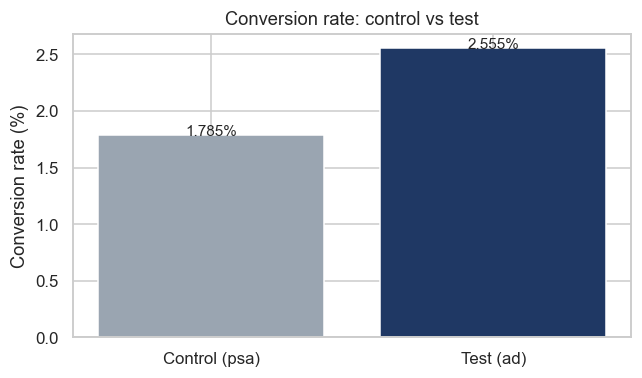

absolute lift: +0.769 percentage points
relative lift: +43.09%
allocation: 96.0% ad vs 4.0% psa  (SRM test p = 0.00e+00)
the control is a small holdout rather than a balanced arm - read the test as
holdout vs treatment, not as a textbook 50/50 split.


In [2]:
summary = (df.groupby('group')
             .agg(users=('converted', 'size'),
                  conversions=('converted', 'sum'),
                  conv_rate=('converted', 'mean'))
             .assign(conv_rate_pct=lambda d: (d.conv_rate * 100).round(3)))
print(summary[['users', 'conversions', 'conv_rate_pct']].to_string())

ad = summary.loc['ad']
psa = summary.loc['psa']
abs_lift = ad.conv_rate - psa.conv_rate
rel_lift = abs_lift / psa.conv_rate

fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(['Control (psa)', 'Test (ad)'], [psa.conv_rate * 100, ad.conv_rate * 100],
              color=['#9aa5b1', '#1f3864'])
for b, v in zip(bars, [psa.conv_rate * 100, ad.conv_rate * 100]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.0004, f'{v:.3f}%', ha='center', fontsize=10)
ax.set_ylabel('Conversion rate (%)')
ax.set_title('Conversion rate: control vs test')
plt.tight_layout()
plt.savefig(OUT / 'fig_conv_rates.png', bbox_inches='tight')
plt.show()

print(f'absolute lift: {abs_lift*100:+.3f} percentage points')
print(f'relative lift: {rel_lift:+.2%}')

# sample-ratio check: this dataset is not a 50/50 split, it is a small holdout
srm = stats.chisquare([int(ad.users), int(psa.users)])
print(f'allocation: {ad.users/(ad.users+psa.users):.1%} ad vs {psa.users/(ad.users+psa.users):.1%} psa'
      f'  (SRM test p = {srm.pvalue:.2e})')
print('the control is a small holdout rather than a balanced arm - read the test as')
print('holdout vs treatment, not as a textbook 50/50 split.')


## 3. Is the difference statistically significant?

A two-proportion z-test compares the conversion rates while accounting for sample size. The chi-square test answers the same question with a different statistic; both should agree.


In [3]:
n_ad, x_ad = int(ad.users), int(ad.conversions)
n_psa, x_psa = int(psa.users), int(psa.conversions)

counts = np.array([x_ad, x_psa])
nobs = np.array([n_ad, n_psa])
z_stat, p_value = proportions_ztest(counts, nobs, alternative='two-sided')

# 95% CI on the absolute difference (unpooled standard error)
se_diff = np.sqrt(ad.conv_rate * (1 - ad.conv_rate) / n_ad + psa.conv_rate * (1 - psa.conv_rate) / n_psa)
ci_low, ci_high = abs_lift - 1.96 * se_diff, abs_lift + 1.96 * se_diff

# chi-square on the 2x2 table
table = np.array([[x_ad, n_ad - x_ad], [x_psa, n_psa - x_psa]])
chi2, p_chi2, dof, _ = stats.chi2_contingency(table, correction=False)

print(f'z-statistic          {z_stat:.3f}')
print(f'p-value (z-test)     {p_value:.3e}')
print(f'chi-square           {chi2:.3f} (dof {dof}), p = {p_chi2:.3e}')
print(f'95% CI on lift       [{ci_low*100:+.3f}, {ci_high*100:+.3f}] percentage points')
print()
if p_value < 0.05 and ci_low > 0:
    print('RESULT: the lift is statistically significant at 95% confidence and the CI excludes zero.')
else:
    print('RESULT: cannot reject the null hypothesis at 95% confidence.')


z-statistic          7.370
p-value (z-test)     1.705e-13
chi-square           54.318 (dof 1), p = 1.705e-13
95% CI on lift       [+0.595, +0.943] percentage points

RESULT: the lift is statistically significant at 95% confidence and the CI excludes zero.


### Confidence interval on the relative lift

The absolute difference is what the finance team needs; the relative lift is what marketing quotes. A bootstrap of 5,000 resamples gives a robust interval for the percentage improvement.


relative lift      +43.09%
95% bootstrap CI   [+30.35%, +57.92%]
P(lift <= 0)       0.0000%


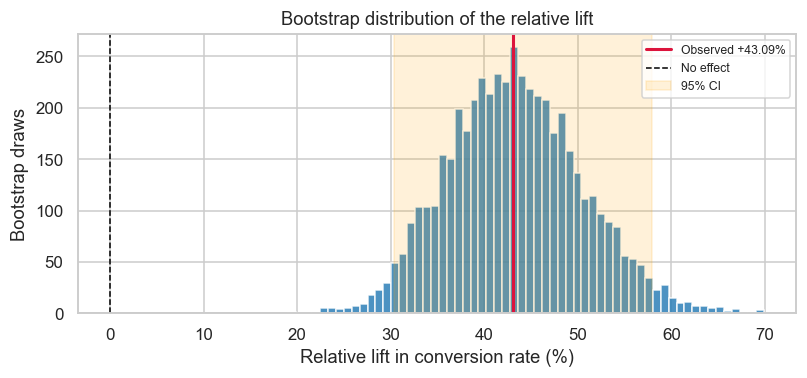

In [4]:
B = 5000
boot = np.empty(B)
rng = np.random.default_rng(42)
ad_flags = df.loc[df.group == 'ad', 'converted'].to_numpy()
psa_flags = df.loc[df.group == 'psa', 'converted'].to_numpy()

for i in range(B):
    a = rng.choice(ad_flags, n_ad, replace=True).mean()
    p = rng.choice(psa_flags, n_psa, replace=True).mean()
    boot[i] = a / p - 1

rel_lo, rel_hi = np.percentile(boot, [2.5, 97.5])
print(f'relative lift      {rel_lift:+.2%}')
print(f'95% bootstrap CI   [{rel_lo:+.2%}, {rel_hi:+.2%}]')
print(f'P(lift <= 0)       {(boot <= 0).mean():.4%}')

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(boot * 100, bins=60, color='#2c7fb8', alpha=.85)
ax.axvline(rel_lift * 100, color='crimson', lw=2, label=f'Observed {rel_lift*100:+.2f}%')
ax.axvline(0, color='black', ls='--', lw=1, label='No effect')
ax.axvspan(rel_lo * 100, rel_hi * 100, color='orange', alpha=.15, label='95% CI')
ax.set_xlabel('Relative lift in conversion rate (%)')
ax.set_ylabel('Bootstrap draws')
ax.set_title('Bootstrap distribution of the relative lift')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / 'fig_lift_ci.png', bbox_inches='tight')
plt.show()


## 4. Power and sample-size sanity check

With hundreds of thousands of users per arm, even a tiny effect is detectable. The question is whether the test was large enough to trust a small difference — and whether the effect is big enough to matter.


In [5]:
p1, p2 = psa.conv_rate, ad.conv_rate
h = 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))
power = NormalIndPower().power(effect_size=abs(h), nobs1=n_psa,
                               alpha=0.05, ratio=n_ad / n_psa)
print(f'effect size h      {abs(h):.5f}')
print(f'achieved power     {power:.3f}  (target 0.80)')
print(f'sample size        {n_ad:,} test vs {n_psa:,} control')

lift_needed = stats.norm.ppf(0.975) * np.sqrt(p1 * (1 - p1) / n_psa + p1 * (1 - p1) / n_ad)
print(f'minimum detectable absolute lift at this size: {lift_needed*100:.3f} pp')


effect size h      0.05300
achieved power     1.000  (target 0.80)
sample size        564,577 test vs 23,524 control
minimum detectable absolute lift at this size: 0.173 pp


## 5. Bonus — what would 100% rollout mean?

If every user saw the ad, expected purchases = total users × test conversion rate; the difference against the control rate is the incremental volume.


users in experiment      588,101
purchases if all see ad  15,024
purchases if all see psa 10,500
incremental purchases    4,524  (95% CI 3,500 to 5,548)
that is +0.769 extra purchases per 100 users


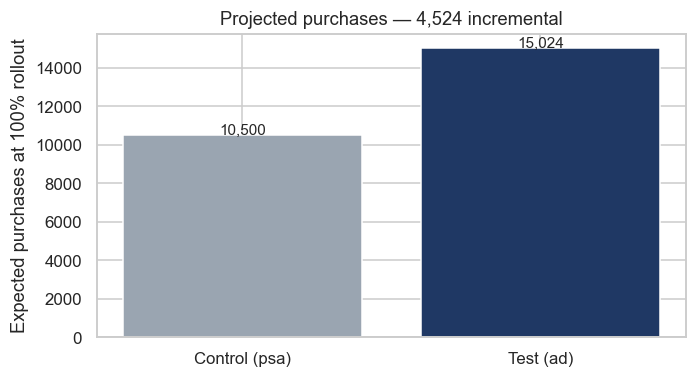

In [6]:
total_users = len(df)
expected_ad = total_users * ad.conv_rate
expected_psa = total_users * psa.conv_rate
incremental = expected_ad - expected_psa
incremental_lo = total_users * ci_low
incremental_hi = total_users * ci_high

print(f'users in experiment      {total_users:,}')
print(f'purchases if all see ad  {expected_ad:,.0f}')
print(f'purchases if all see psa {expected_psa:,.0f}')
print(f'incremental purchases    {incremental:,.0f}  (95% CI {incremental_lo:,.0f} to {incremental_hi:,.0f})')
print(f'that is {incremental/total_users*100:+.3f} extra purchases per 100 users')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(['Control (psa)', 'Test (ad)'], [expected_psa, expected_ad], color=['#9aa5b1', '#1f3864'])
ax.set_ylabel('Expected purchases at 100% rollout')
ax.set_title(f'Projected purchases — {incremental:,.0f} incremental')
for i, v in enumerate([expected_psa, expected_ad]):
    ax.text(i, v + 40, f'{v:,.0f}', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig(OUT / 'fig_rollout.png', bbox_inches='tight')
plt.show()


## 6. Secondary read — does ad exposure matter?

`total ads` is how many ads a user saw. If the ad worked through repetition, conversion should rise with exposure. Comparing conversion by exposure band within the test group tests that.


group        ad     psa
band                   
1-25      0.599   0.610
26-50     3.542   2.658
51-100   11.631   5.774
101-200  17.677  10.638
201-500  15.367  15.900
500+     17.522  10.526


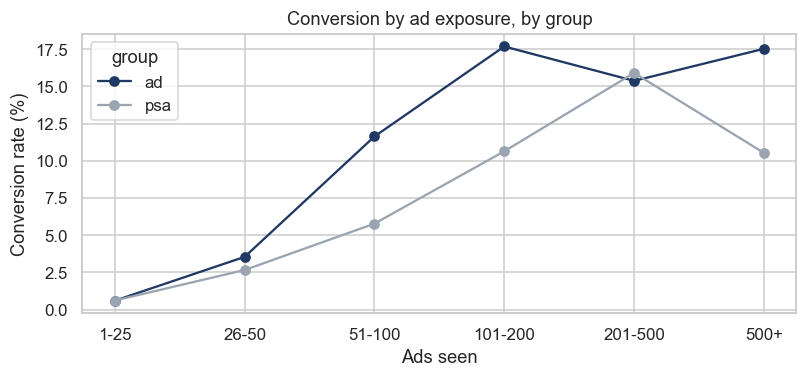

correlation(total ads, converted) within test group: 0.219


In [7]:
bands = pd.cut(df.total_ads, [0, 25, 50, 100, 200, 500, 2000],
               labels=['1-25', '26-50', '51-100', '101-200', '201-500', '500+'])
exposure = (df.assign(band=bands).groupby(['group', 'band'], observed=True)
              .converted.agg(['size', 'mean']).reset_index())
exposure['conv_pct'] = exposure['mean'] * 100

pivot = exposure.pivot(index='band', columns='group', values='conv_pct')
print(pivot.round(3).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.6))
pivot.plot(ax=ax, marker='o', color=['#1f3864', '#9aa5b1'])
ax.set_ylabel('Conversion rate (%)')
ax.set_xlabel('Ads seen')
ax.set_title('Conversion by ad exposure, by group')
plt.tight_layout()
plt.savefig(OUT / 'fig_exposure.png', bbox_inches='tight')
plt.show()

corr = df[df.group == 'ad'][['total_ads', 'converted']].corr().iloc[0, 1]
print(f'correlation(total ads, converted) within test group: {corr:.3f}')


## 7. Key findings

In [8]:
print('KEY FINDINGS')
print(f'1. Control converted {psa.conv_rate:.3%} ({x_psa:,} of {n_psa:,}); '
      f'test converted {ad.conv_rate:.3%} ({x_ad:,} of {n_ad:,}).')
print(f'2. Absolute lift {abs_lift*100:+.3f} pp, relative lift {rel_lift:+.2%} '
      f'(95% CI {rel_lo:+.2%} to {rel_hi:+.2%}).')
print(f'3. z = {z_stat:.2f}, p = {p_value:.2e} — significant at 95% confidence; '
      f'chi-square agrees (p = {p_chi2:.2e}).')
print(f'4. Power {power:.2f}, so the test is large enough for an effect of this size.')
print(f'5. At 100% rollout the ad yields about {incremental:,.0f} extra purchases '
      f'(CI {incremental_lo:,.0f} to {incremental_hi:,.0f}).')
print(f'6. Material in relative terms (+{rel_lift:.0%}) but under one percentage point per user')
print(f'   ({abs_lift*100:.3f} pp), so it is a real, modest win rather than a breakthrough.')
print('7. Allocation is ~96/4, not 50/50: this is a holdout-versus-treatment test.')


KEY FINDINGS
1. Control converted 1.785% (420 of 23,524); test converted 2.555% (14,423 of 564,577).
2. Absolute lift +0.769 pp, relative lift +43.09% (95% CI +30.35% to +57.92%).
3. z = 7.37, p = 1.71e-13 — significant at 95% confidence; chi-square agrees (p = 1.71e-13).
4. Power 1.00, so the test is large enough for an effect of this size.
5. At 100% rollout the ad yields about 4,524 extra purchases (CI 3,500 to 5,548).
6. Material in relative terms (+43%) but under one percentage point per user
   (0.769 pp), so it is a real, modest win rather than a breakthrough.
7. Allocation is ~96/4, not 50/50: this is a holdout-versus-treatment test.
